# Análise do Problema de Classificação

Neste notebook é analisado o problema de classificação do risco de burnout.

## Carregamento do dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import f_oneway
from scipy.stats import chi2_contingency

df_clean = pd.read_csv(
    "../datasets/dataset_clean.csv"
)

df_clean.head()

,Person_ID,Age,Gender,Country,Occupation,Education_Level,Employment_Status,Monthly_Income_USD,Work_Hours_Per_Week,Remote_Work,...,Family_History_Mental_Illness,Therapy_Attendance,Support_System,Life_Satisfaction,Productivity_Score,Absenteeism_Days,Burnout_Score,Mental_Health_Status,AI_Wellness_Recommendation,Burnout_Risk
0,1,58.0,Male,United States,Marketing Manager,Diploma,Employed,2786.0,67,Hybrid,...,No,Yes,Average,6.0,19.0,2,82,Critical,Practice Mindfulness,High
1,2,24.0,Female,Pakistan,Freelancer,Bachelor,Student,8027.0,44,Hybrid,...,Yes,No,Good,4.0,27.0,22,64,Critical,Reduce Workload,Moderate
2,3,59.0,Male,Malaysia,Accountant,PhD,Employed,3177.0,60,No,...,Yes,No,Average,4.0,51.0,17,50,Needs Attention,Increase Physical Activity,Moderate
3,4,65.0,Other,Mexico,Chef,Master,Self-Employed,4093.0,25,Yes,...,No,Yes,Good,7.0,83.0,14,16,Healthy,Maintain Healthy Routine,Low
4,5,64.0,Other,Japan,Farmer,Diploma,Student,6231.0,52,No,...,Yes,No,Poor,9.0,61.0,4,26,Healthy,Reduce Workload,Low


# Definição da Variável-Alvo para Classificação

A variável escolhida como alvo é `Burnout_Risk`.

Ela é uma variável categórica que possui três classes:

- Low;
- Moderate;
- High.

A variável é adequada para um problema de classificação porque o objetivo será prever a categoria de risco de burnout de cada indivíduo a partir das demais características disponíveis.

# Distribuição das Classes de Burnout Risk

In [2]:
distribuicao = df_clean["Burnout_Risk"].value_counts()

print("Quantidade por classe:")
display(distribuicao)

print("\nPercentual por classe:")
display(
    df_clean["Burnout_Risk"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Quantidade por classe:


Burnout_Risk
Low         25369
Moderate    14780
High         9851
Name: count, dtype: int64


Percentual por classe:


Burnout_Risk
Low         50.74
Moderate    29.56
High        19.70
Name: proportion, dtype: float64

## Visualização da Distribuição das Classes

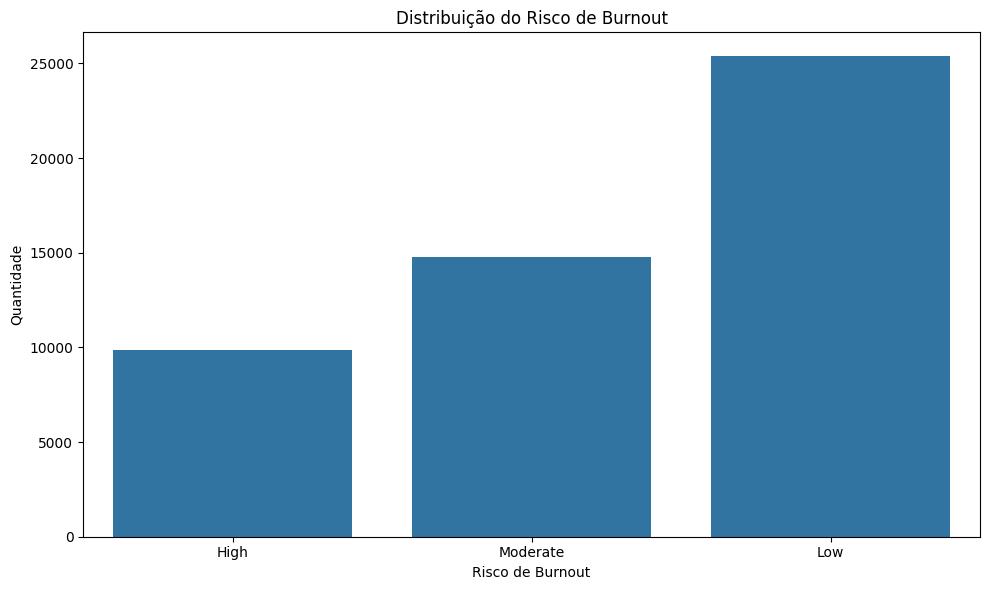

In [3]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df_clean,
    x="Burnout_Risk"
)

plt.title("Distribuição do Risco de Burnout")
plt.xlabel("Risco de Burnout")
plt.ylabel("Quantidade")

plt.tight_layout()

plt.savefig(
    "../reports/figures/burnout_risk_distribution.png",
    dpi=300
)

plt.show()

# Comparar as features por classe

Anxiety_Score x Burnout_Risck:

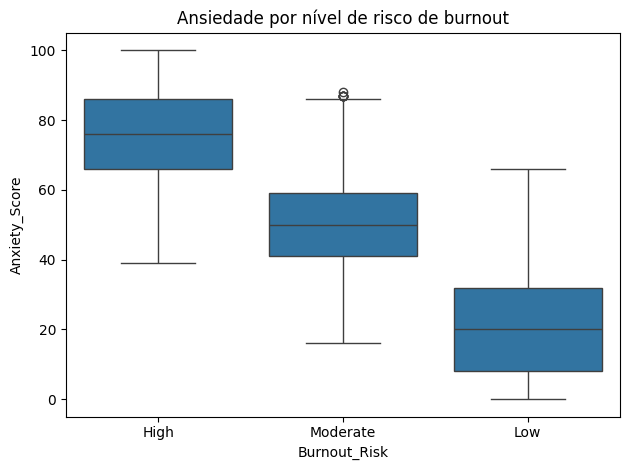

In [9]:
sns.boxplot(
    data=df_clean,
    x="Burnout_Risk",
    y="Anxiety_Score"
)

plt.title("Ansiedade por nível de risco de burnout")
plt.tight_layout()

plt.savefig(
    "../reports/figures/risk_vs_anxiety.png",
    dpi=300
)

plt.show()

Productivity_Score x Burnout_Risck:

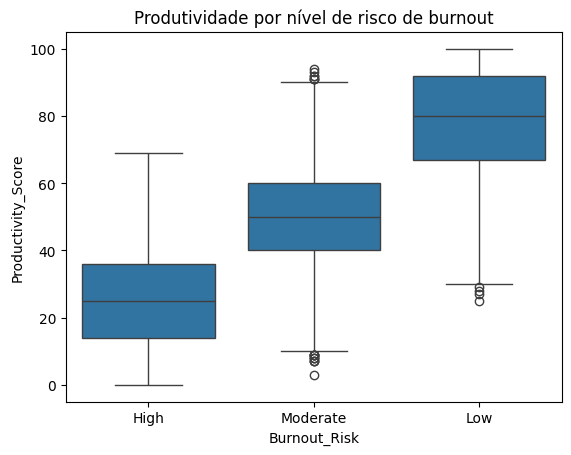

In [5]:
sns.boxplot(
    data=df_clean,
    x="Burnout_Risk",
    y="Productivity_Score"
)

plt.title("Produtividade por nível de risco de burnout")
plt.show()

# Analisar médias por classe

In [4]:
df_clean.groupby(
    "Burnout_Risk"
)[
    [
        "Burnout_Score",
        "Anxiety_Score",
        "Depression_Score",
        "Productivity_Score",
        "Emotional_Stability",
        "Mood_Score",
        "Work_Hours_Per_Week"
    ]
].mean()

,Burnout_Score,Anxiety_Score,Depression_Score,Productivity_Score,Emotional_Stability,Mood_Score,Work_Hours_Per_Week
Burnout_Risk,,,,,,,
High,79.186174,75.598213,75.733428,25.351741,23.994823,25.196325,57.778804
Low,18.677717,20.914541,21.110134,78.347984,79.004848,78.789546,37.413221
Moderate,51.163464,50.473207,50.548309,49.819824,49.286739,49.754263,49.322936


# Análise Estatística com ANOVA

A ANOVA será utilizada para verificar se existem diferenças estatisticamente significativas nas médias das variáveis numéricas entre as classes de Burnout_Risk.

In [6]:
variaveis_anova = [
    "Anxiety_Score",
    "Depression_Score",
    "Mood_Score",
    "Emotional_Stability",
    "Productivity_Score",
    "Work_Hours_Per_Week"
]

resultados_anova = []

for coluna in variaveis_anova:

    grupos = [
        grupo[coluna].dropna()
        for _, grupo in df_clean.groupby("Burnout_Risk")
    ]

    resultado = f_oneway(*grupos)

    resultados_anova.append({
        "Variável": coluna,
        "F": resultado.statistic,
        "p-valor": resultado.pvalue
    })

anova_df = pd.DataFrame(resultados_anova)

display(anova_df)

,Variável,F,p-valor
0,Anxiety_Score,58720.708232,0.0
1,Depression_Score,54026.013718,0.0
2,Mood_Score,54940.309289,0.0
3,Emotional_Stability,56614.473980,0.0
4,Productivity_Score,48207.954468,0.0
5,Work_Hours_Per_Week,11146.021254,0.0


# Análise das Variáveis Categóricas com Qui-Quadrado

O teste qui-quadrado será utilizado para verificar possíveis associações entre variáveis categóricas e a variável-alvo `Burnout_Risk`.

In [7]:
variaveis_categoricas = [
    coluna
    for coluna in df_clean.select_dtypes(include="object").columns
    if coluna != "Burnout_Risk"
]

resultados_chi2 = []

for coluna in variaveis_categoricas:

    tabela = pd.crosstab(
        df_clean[coluna],
        df_clean["Burnout_Risk"]
    )

    chi2, p, dof, expected = chi2_contingency(tabela)

    resultados_chi2.append({
        "Variável": coluna,
        "Qui-quadrado": chi2,
        "p-valor": p
    })

chi2_df = pd.DataFrame(
    resultados_chi2
).sort_values(
    "p-valor"
)

display(chi2_df)

,Variável,Qui-quadrado,p-valor
6,Sleep_Quality,1774.238202,0.000000
7,Stress_Level,49792.516883,0.000000
12,Chronic_Stress,25694.407312,0.000000
16,Mental_Health_Status,94589.976193,0.000000
11,Healthy_Diet,11.725887,0.002843
9,Alcohol_Consumption,5.920415,0.051808
10,Smoking,3.970784,0.137327
2,Occupation,43.273833,0.256313
1,Country,51.144831,0.351245
8,Exercise_Frequency,5.936216,0.430373


# Exemplo de Associação entre Stress Level e Burnout Risk

In [8]:
tabela_stress = pd.crosstab(
    df_clean["Stress_Level"],
    df_clean["Burnout_Risk"]
)

display(tabela_stress)

Burnout_Risk,High,Low,Moderate
Stress_Level,,,
High,6456,0,693
Low,0,20437,1150
Moderate,3395,4932,12937


# Análise de Possível Data Leakage

Algumas variáveis precisam ser analisadas com cuidado antes de serem utilizadas como características do modelo.

`Burnout_Score` não será utilizado como feature porque representa uma pontuação diretamente relacionada ao risco de burnout e será tratado como informação potencialmente derivada do mesmo fenômeno.

`Mental_Health_Status` também será excluída por poder representar uma informação derivada ou muito próxima da classificação de risco.

`AI_Wellness_Recommendation` será excluída porque pode ter sido produzida a partir de informações relacionadas ao estado de saúde e ao burnout.

`Person_ID` será excluído por ser apenas um identificador.

# Principais Variáveis para o Problema de Classificação

As principais variáveis inicialmente recomendadas são:

- `Anxiety_Score`;
- `Depression_Score`;
- `Mood_Score`;
- `Emotional_Stability`;
- `Productivity_Score`;
- `Work_Hours_Per_Week`;
- `Sleep_Hours`;
- `Physical_Activity_Hours`;
- `Meditation_Minutes`;
- `Screen_Time_Hours`.

As análises de correlação, comparação das médias, boxplots e testes estatísticos indicam que essas variáveis apresentam potencial para diferenciar os níveis de risco de burnout.

# Recomendações de Algoritmos de Classificação

Como etapa inicial de modelagem, recomenda-se testar:

- Regressão Logística;
- Random Forest Classifier;
- Gradient Boosting;
- K-Nearest Neighbors (KNN).

A avaliação deve considerar não apenas a acurácia, mas também precisão, recall, F1-score e matriz de confusão. Atenção especial deve ser dada à classe `High`, que possui menor quantidade de registros que a classe `Low`.

# Conclusões da Análise de Classificação

A variável `Burnout_Risk` apresenta três classes: Low, Moderate e High. As análises realizadas indicam diferenças importantes entre as classes para variáveis relacionadas à ansiedade, depressão, humor, estabilidade emocional, produtividade e horas de trabalho.

Os testes estatísticos reforçam que diversas características apresentam associação ou diferenças significativas entre os grupos. Entretanto, variáveis que possam causar vazamento de informação devem ser removidas antes da modelagem.

Como próximos passos, recomenda-se comparar algoritmos de classificação utilizando métricas como precisão, recall, F1-score e matriz de confusão, dando atenção especial à identificação da classe High.